# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv"

df = pd.read_csv(url)

print("First 5 rows:")
display(df.head())

print("Dataset information:")
df.info()

print("Summary statistics:")
display(df.describe(include='all'))

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

First 5 rows:


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB
Summary statistics:


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,14850.475563,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000


Missing values:
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64
Duplicate rows: 3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. In the initial preview, I see some unusual values like -65600, the highest age is 132, and that someone has 3345 accounts.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:
# Make a copy of the original data
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove clearly unusual values
df_clean = df_clean[(df_clean['income'] >= 0) & (df_clean['age'] >= 18) & (df_clean['age'] <= 100) & (df_clean['num_accts'] <= 20)].copy()

# Fill missing new_car values with the most common value
df_clean['new_car'] = df_clean['new_car'].fillna(df_clean['new_car'].mode()[0])

# Remove customer ID and product
df_clean = df_clean.drop(columns=['customer_id', 'product'])

# Check cleaned data
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Missing values:", df_clean.isnull().sum().sum())
display(df_clean.head())

Original rows: 29504
Cleaned rows: 29497
Missing values: 0


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
2,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
3,0,4330,0,24,2,2,1,0,0.0,1,3,1,0
4,0,4330,0,22,2,1,1,0,0.0,3,0,0,0
6,0,4330,0,22,2,1,1,0,0.0,3,0,0,0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed duplicate rows and clearly unusual values, I filled missing new car values with the most common value, I removed the customer ID and product, and I checked the clean data. I did this because it reduces the impact of unusual values, while keeping the most amount of data.

2.6 I removed customer_id because it doesn't give anything useful, it just identifies them. I also removed product because it only shows up after the customer answers the call, so it's not reliable.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [6]:
# Convert answered to Boolean
df_clean['answered'] = df_clean['answered'].astype(bool)

# Clean and convert gender values
df_clean['female'] = (df_clean['female'].astype(str).str.strip().str.upper().replace({'M': 0, 'F': 1}))

# Check for any unexpected gender values
print(df_clean['female'].value_counts(dropna=False))

# Convert numeric columns to integers
integer_cols = ['income', 'age', 'job', 'num_dependents', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile']

for col in integer_cols:
    df_clean[col] = df_clean[col].astype(int)

# Convert gender separately
df_clean['female'] = pd.to_numeric(df_clean['female'], errors='coerce')

# Check data types and missing values
print(df_clean.dtypes)
print(df_clean.isnull().sum())

female
0    27898
1     1598
0        1
Name: count, dtype: int64
answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [7]:
categorical_cols = ['female', 'job', 'rent', 'own_res', 'new_car']

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')

print(df_clean.dtypes)

answered              bool
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent              category
own_res           category
new_car           category
chk_acct             int64
sav_acct             int64
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



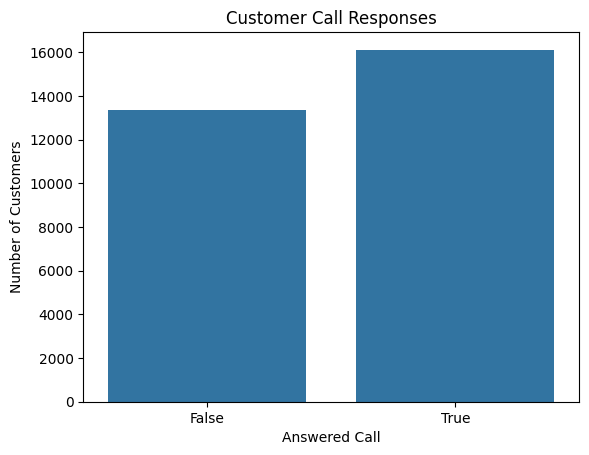

In [8]:
sns.countplot(data=df_clean, x='answered')
plt.title("Customer Call Responses")
plt.xlabel("Answered Call")
plt.ylabel("Number of Customers")
plt.show()


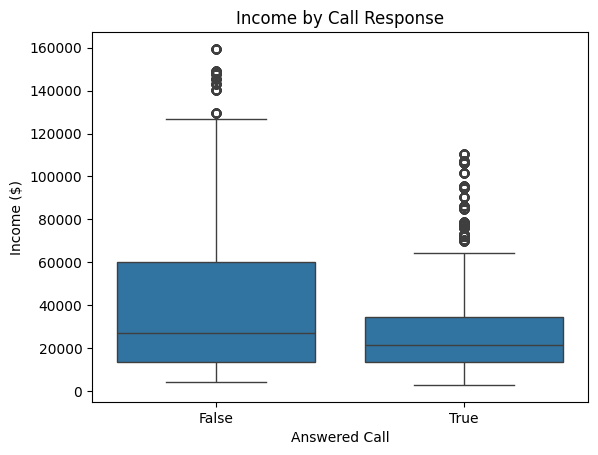

In [9]:
sns.boxplot(data=df_clean, x='answered', y='income')
plt.title("Income by Call Response")
plt.xlabel("Answered Call")
plt.ylabel("Income ($)")
plt.show()

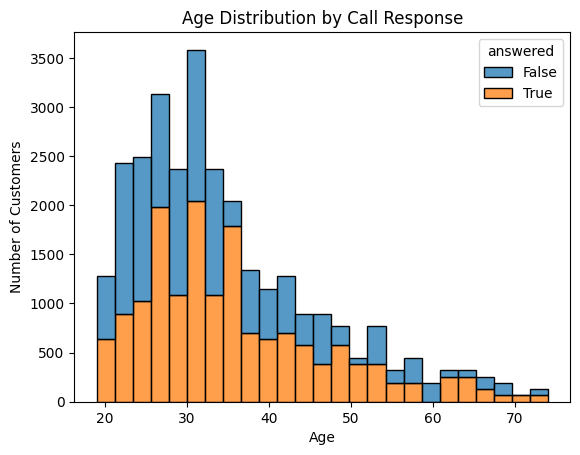

In [10]:
sns.histplot(data=df_clean, x='age', hue='answered', bins=25, multiple='stack')
plt.title("Age Distribution by Call Response")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

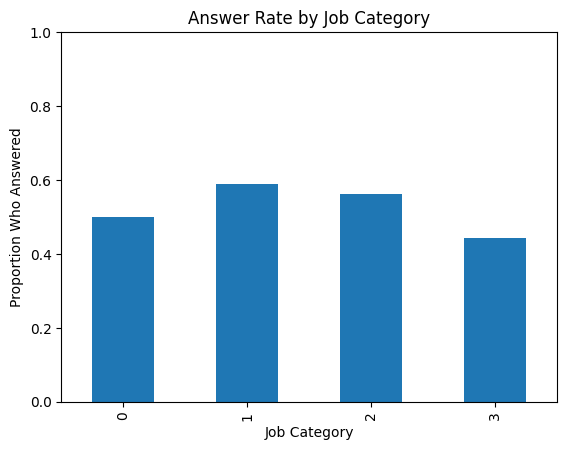

In [11]:
job_rates = df_clean.groupby('job', observed=True)['answered'].mean()

job_rates.plot(kind='bar')
plt.title("Answer Rate by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Proportion Who Answered")
plt.ylim(0, 1)
plt.show()

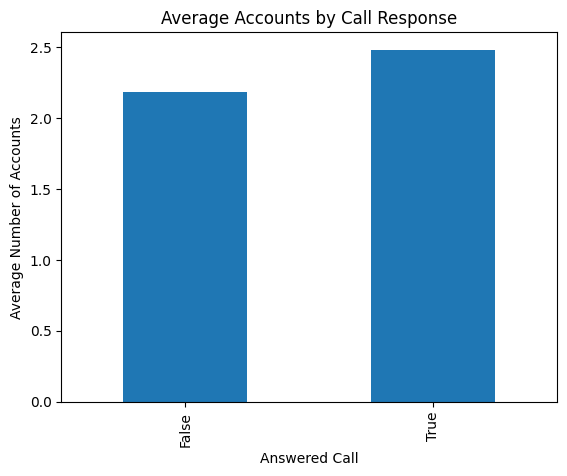

In [12]:
account_means = df_clean.groupby('answered')['num_accts'].mean()

account_means.plot(kind='bar')
plt.title("Average Accounts by Call Response")
plt.xlabel("Answered Call")
plt.ylabel("Average Number of Accounts")
plt.show()

In [13]:
# For 3.6 - Variables that show the strongest relationship with the target
eda_features = df_clean.drop(columns='answered').copy()

for col in eda_features.select_dtypes(include='category').columns:
    eda_features[col] = eda_features[col].astype(int)

relationships = eda_features.corrwith(df_clean['answered'].astype(int))

print(relationships.reindex(relationships.abs().sort_values(ascending=False).index))

chk_acct          0.345716
income           -0.223596
sav_acct          0.178807
num_accts         0.123616
mobile            0.121742
new_car          -0.118930
own_res           0.115401
rent             -0.074903
age               0.074590
female           -0.070888
job              -0.064100
num_dependents   -0.006705
dtype: float64


### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Based on the chart above, the variable that shows the strongest relationship with the target variable was the chk_acct, sav_acct, and income.

3.7. I found that the num_dependents was -0.00. Although, it has almost no relationship with the target variable, I don't think it means we should remove it right away.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [14]:
base_probability = df_clean['answered'].mean()

print("Base probability of answering:", base_probability)
print("Answer percentage:", base_probability * 100)

baseline_accuracy = max(base_probability, 1 - base_probability)

print("Majority-class baseline accuracy:", baseline_accuracy)

Base probability of answering: 0.546699664372648
Answer percentage: 54.669966437264804
Majority-class baseline accuracy: 0.546699664372648


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [15]:
X = df_clean.drop(columns='answered').copy()
y = df_clean['answered'].astype(int)

# Convert categorical features to numeric codes
for col in X.select_dtypes(include='category').columns:
    X[col] = X[col].astype(int)

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 23597
Testing rows: 5900


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

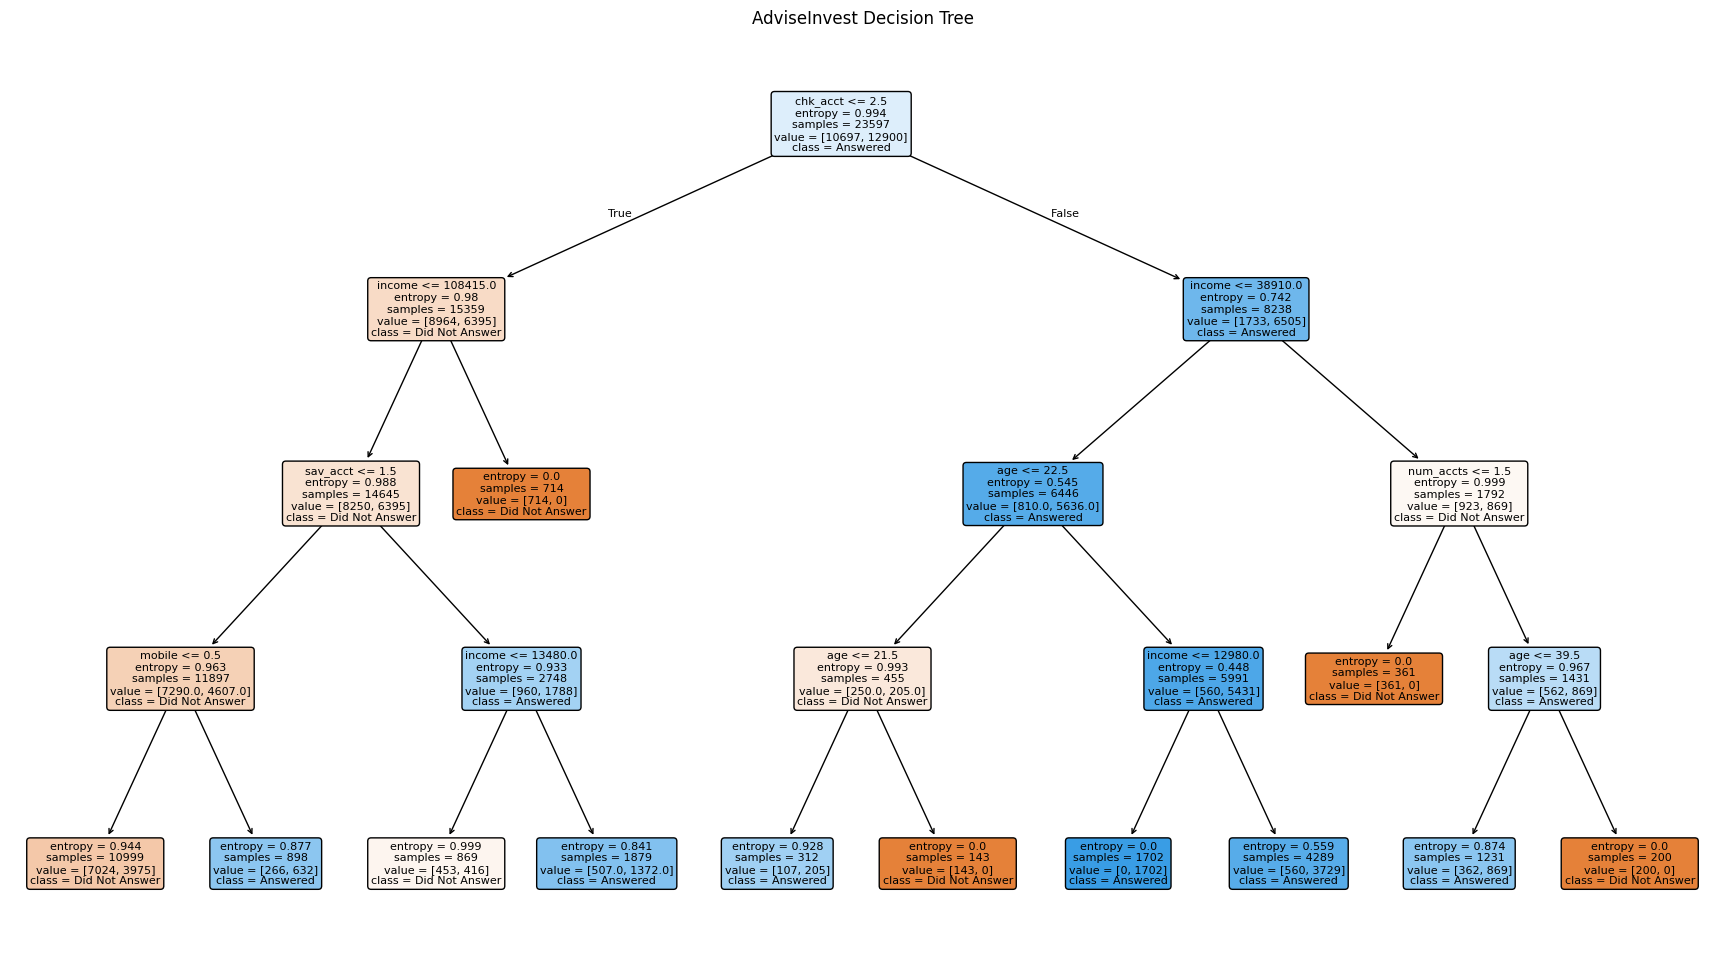

In [16]:
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

clf.fit(X_train, y_train)

plt.figure(figsize=(22, 12))
plot_tree(clf, feature_names=X.columns, class_names=['Did Not Answer', 'Answered'], filled=True, rounded=True, fontsize=8)
plt.title("AdviseInvest Decision Tree")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [17]:
y_pred = clf.predict(X_test)

model_accuracy = accuracy_score(y_test, y_pred)

print("Base probability:", base_probability)
print("Baseline accuracy:", baseline_accuracy)
print("Decision tree accuracy:", model_accuracy)
print("Improvement:", model_accuracy - baseline_accuracy)

Base probability: 0.546699664372648
Baseline accuracy: 0.546699664372648
Decision tree accuracy: 0.7371186440677966
Improvement: 0.19041897969514854


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The probability from the model measures how often the model predicted whether customers answered or not accurately which was 73.71%. On the other hand, the base probability shows the percentage of customers who answered which was 54.67%. It improved by 19.04%.

2. Any kind of improvement can be significant for the business. I think the more accurate our predictions are, the more useful the information is for the business (and it also wastes less time).


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [18]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


Confusion Matrix:
[[2236  438]
 [1113 2113]]
True Negatives: 2236
False Positives: 438
False Negatives: 1113
True Positives: 2113


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

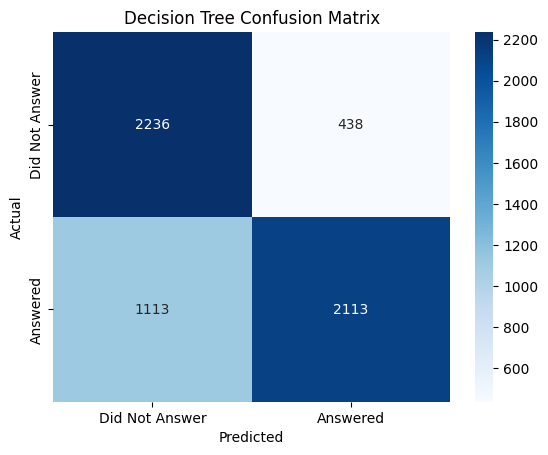

In [19]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Did Not Answer', 'Answered'], yticklabels=['Did Not Answer', 'Answered'])

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [20]:
# Profit from correct predictions of answered calls
profit_model = (tp * 75) - (fp * 25)

print("Model Profit: $", profit_model)

Model Profit: $ 147525


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [21]:
# Calling every customer
total_answered = (y_test == 1).sum()
total_not_answered = (y_test == 0).sum()

default_profit = (total_answered * 75 - total_not_answered * 25)

profit_difference = profit_model - default_profit

print("Default Profit: $", default_profit)
print("Model Profit: $", profit_model)
print("Profit Difference: $", profit_difference)

Default Profit: $ 175100
Model Profit: $ 147525
Profit Difference: $ -27575


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The profit different from using the model profit from the default profit was -$27,575 less profit... Meaning the model actually missed customers who answered.

2. Yes, this is a significant amount for the business, meaning they should improve the model to not reduce their profit amount.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [22]:
# Tune the decision tree
clf_tuned = DecisionTreeClassifier(max_depth=6, random_state=42)

clf_tuned.fit(X_train, y_train)

# Check accuracy
tuned_accuracy = accuracy_score(y_test, clf_tuned.predict(X_test))

print("Original Accuracy:", model_accuracy)
print("Tuned Accuracy:", tuned_accuracy)

Original Accuracy: 0.7371186440677966
Tuned Accuracy: 0.7911864406779661


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [23]:
# Load new customers
new_url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv"
df_new = pd.read_csv(new_url)

# Prepare the same features used in training
X_new = df_new[X_train.columns].copy()
X_new['female'] = X_new['female'].replace({'M': 0, 'F': 1})

# Predict who will answer
df_new['predicted_answered'] = clf_tuned.predict(X_new)

display(df_new[['customer_id', 'predicted_answered']].head())

,customer_id,predicted_answered
0,H1597,0
1,P1446,0
2,E1492,0
3,W5143,0
4,W4927,0


In [24]:
print(df_new['predicted_answered'].value_counts())

predicted_answered
0    578
1    422
Name: count, dtype: int64


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 No, the model did not improve our profit. Even though the model improved accuracy, we still lost profit of $27,575.

6.2 The model could be utilized by the business by using the model to identify which customers are more likely to answer calls and prioritize them. The company should evaluate the model based on probability and not accuracy.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"